In [2]:
%pip install chainladder

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import chainladder as cl

In [4]:
clrd = cl.load_sample("clrd").groupby("LOB").sum()["CumPaidLoss"]
motor = clrd.loc["ppauto"]      # private passenger auto = motor insurance

motor

,12,24,36,48,60,72,84,96,108,120
1988,"3,092,818","5,942,711","7,239,089","7,930,109","8,318,795","8,518,201","8,610,355","8,655,509","8,682,451","8,690,036"
1989,"3,556,683","6,753,435","8,219,551","9,018,288","9,441,842","9,647,917","9,753,014","9,800,477","9,823,747",
1990,"4,015,052","7,478,257","9,094,949","9,945,288","10,371,175","10,575,467","10,671,988","10,728,411",,
1991,"4,065,571","7,564,284","9,161,104","10,006,407","10,419,901","10,612,083","10,713,621",,,
1992,"4,551,591","8,344,021","10,047,179","10,901,995","11,336,777","11,555,121",,,,
1993,"5,020,277","9,125,734","10,890,282","11,782,219","12,249,826",,,,,
1994,"5,569,355","9,871,002","11,641,397","12,600,432",,,,,,
1995,"5,803,124","10,008,734","11,807,279",,,,,,,
1996,"5,835,368","9,900,842",,,,,,,,
1997,"5,754,249",,,,,,,,,


In [5]:

motor.to_frame()

,12,24,36,48,60,72,84,96,108,120
1988-01-01,3092818.0,5942711.0,7239089.0,7930109.0,8318795.0,8518201.0,8610355.0,8655509.0,8682451.0,8690036.0
1989-01-01,3556683.0,6753435.0,8219551.0,9018288.0,9441842.0,9647917.0,9753014.0,9800477.0,9823747.0,NaN
1990-01-01,4015052.0,7478257.0,9094949.0,9945288.0,10371175.0,10575467.0,10671988.0,10728411.0,NaN,NaN
1991-01-01,4065571.0,7564284.0,9161104.0,10006407.0,10419901.0,10612083.0,10713621.0,NaN,NaN,NaN
1992-01-01,4551591.0,8344021.0,10047179.0,10901995.0,11336777.0,11555121.0,NaN,NaN,NaN,NaN
1993-01-01,5020277.0,9125734.0,10890282.0,11782219.0,12249826.0,NaN,NaN,NaN,NaN,NaN
1994-01-01,5569355.0,9871002.0,11641397.0,12600432.0,NaN,NaN,NaN,NaN,NaN,NaN
1995-01-01,5803124.0,10008734.0,11807279.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1996-01-01,5835368.0,9900842.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1997-01-01,5754249.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
tri = motor.to_frame()
tri.index = [str(i)[:4] for i in tri.index]   # show accident years as 1988, 1989, ...
ages = list(tri.columns)

factors = {}
for a, b in zip(ages[:-1], ages[1:]):
    rows = tri[b].notna()                      # only years that have both ages
    factors[a] = tri.loc[rows, b].sum() / tri.loc[rows, a].sum()

factors = pd.Series(factors)
print(factors.round(4))


12     1.8065
24     1.1999
36     1.0889
48     1.0429
60     1.0205
72     1.0100
84     1.0051
96     1.0027
108    1.0009
dtype: float64


In [7]:
full = tri.copy()
for i in full.index:
    for a, b in zip(ages[:-1], ages[1:]):
        if pd.isna(full.loc[i, b]):
            full.loc[i, b] = full.loc[i, a] * factors[a]   # grow last known value

latest = tri.apply(lambda r: r.dropna().iloc[-1], axis=1)  # paid to date
ultimate = full.iloc[:, -1]                                # projected at the last age
reserve = ultimate - latest

result = pd.DataFrame({"Paid to date": latest, "Ultimate": ultimate, "Reserve": reserve}).round(0)
result.loc["Total"] = result.sum()
result

,Paid to date,Ultimate,Reserve
1988,8690036.0,8690036.0,0.0
1989,9823747.0,9832329.0,8582.0
1990,10728411.0,10766997.0,38586.0
1991,10713621.0,10807345.0,93724.0
1992,11555121.0,11773294.0,218173.0
1993,12249826.0,12736374.0,486548.0
1994,12600432.0,13662461.0,1062029.0
1995,11807279.0,13940149.0,2132870.0
1996,9900842.0,14026304.0,4125462.0
1997,5754249.0,14726733.0,8972484.0


In [8]:
model = cl.Chainladder().fit(motor)
print(model.ibnr_.sum().sum())
print(result.loc["Total", "Reserve"])

17138458.52214752
17138458.0


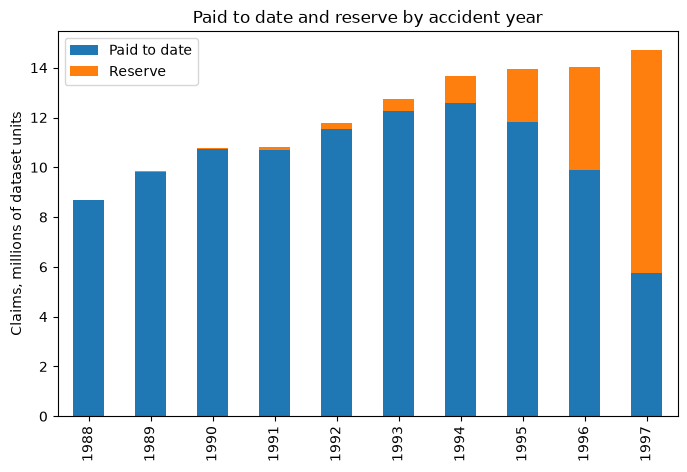

In [9]:
(result.drop("Total")[["Paid to date", "Reserve"]] / 1e6).plot(
    kind="bar", stacked=True, figsize=(8, 5),
    title="Paid to date and reserve by accident year")
plt.ylabel("Claims, millions of dataset units")
plt.savefig("reserve_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
mack = cl.MackChainladder().fit(motor)
print(mack.summary_)
print(mack.total_mack_std_err_)

          Latest          IBNR      Ultimate   Mack Std Err
1988   8690036.0           NaN  8.690036e+06            NaN
1989   9823747.0  8.582038e+03  9.832329e+06    1653.899192
1990  10728411.0  3.858594e+04  1.076700e+07    6762.141384
1991  10713621.0  9.372411e+04  1.080735e+07    7330.445075
1992  11555121.0  2.181730e+05  1.177329e+07   13375.966529
1993  12249826.0  4.865484e+05  1.273637e+07   30494.603539
1994  12600432.0  1.062029e+06  1.366246e+07   57403.080639
1995  11807279.0  2.132870e+06  1.394015e+07   98824.021841
1996   9900842.0  4.125462e+06  1.402630e+07  213291.577091
1997   5754249.0  8.972484e+06  1.472673e+07  633916.704682
columns      CumPaidLoss
(ppauto,)  699005.329564
